In [ ]:
# 1. Introdução - Definição do Problema


Introdução à Previsão de Custos Médicos com Machine Learning

Nos últimos anos, a crescente complexidade e os custos do sistema de saúde têm gerado desafios significativos para seguradoras, prestadores de serviços médicos e pacientes. Dentre os diversos fatores que impactam os gastos com saúde, a previsão precisa dos custos médicos tem se mostrado uma ferramenta essencial para otimizar processos, melhorar a alocação de recursos e aumentar a eficiência financeira. O uso de machine learning (aprendizado de máquina) tem emergido como uma solução promissora para enfrentar esses desafios.

O aprendizado de máquina é uma subárea da inteligência artificial que permite que os sistemas aprendam a partir de dados históricos, sem a necessidade de programação explícita para cada tarefa. No contexto dos custos médicos, algoritmos de machine learning podem analisar grandes volumes de dados — como informações de pacientes, histórico de tratamentos, diagnósticos e características demográficas — para identificar padrões e prever com maior precisão os custos de tratamentos futuros.

Essas previsões podem ser usadas tanto por seguradoras para definir prêmios de seguro mais adequados quanto por hospitais e clínicas para planejar melhor os recursos necessários. Além disso, ao antecipar custos médicos com precisão, as partes envolvidas podem tomar decisões mais informadas sobre a alocação de recursos, negociação de contratos e planejamento estratégico.

Com o uso de técnicas como regressão, redes neurais, árvores de decisão e algoritmos de aprendizado supervisionado, é possível criar modelos que não apenas preveem o valor total dos custos, mas também identificam os principais fatores que influenciam esses custos, como o tipo de tratamento, comorbidades e tempo de hospitalização. Isso proporciona uma visão mais clara e detalhada das despesas médicas, permitindo um gerenciamento financeiro mais eficaz e uma melhor experiência para os pacientes.


2. Coleta de Dados

In [2]:
import pandas as pd #biblioteca para processamento de dados

In [6]:
dados = pd.read_csv('insurance.csv') #lendo o arquivo csv

In [8]:
dados.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [9]:
dados.dtypes

,0
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


3. Analise de Dados

In [10]:
dados.describe() #medidas e estasticas

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


array([[<Axes: title={'center': 'age'}>, <Axes: title={'center': 'bmi'}>],
       [<Axes: title={'center': 'children'}>,
        <Axes: title={'center': 'charges'}>]], dtype=object)

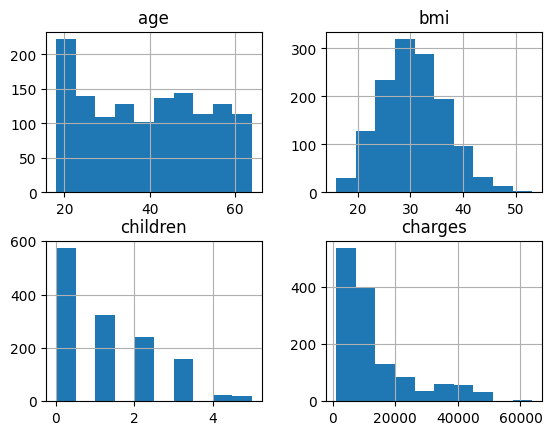

In [11]:
dados.hist()

#4. Pré-processamento

-tratar dados faltantes
-tratar textos
-tratar duplicados

In [12]:
dados.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [13]:
dados.duplicated().sum()

np.int64(1)

In [15]:
dados.drop_duplicates(inplace=True)

In [16]:
dados.head(1)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.9,0,yes,southwest,16884.924


In [34]:
dados['sex'] = dados ['sex'].map({'male': 0, 'female': 1})
dados['smoker'] = dados ['smoker'].map({'yes': 1, 'no': 0})

# KNN - Regressão

In [35]:
X = dados[["bmi","smoker"]]
Y = dados['charges']

In [36]:
from sklearn.neighbors import KNeighborsRegressor

In [37]:
knn = KNeighborsRegressor(n_neighbors=5)

In [38]:
knn.fit(X,Y)

KNeighborsRegressor()

In [40]:
knn.predict(X)

array([23379.49643 ,  8574.750366,  7848.630584, ..., 11359.578412,
        5327.44    , 22335.73361 ])